# Job Matching, Historical Hiring Bias, and Fairlearn

**A guided investigation | 2 hours | Python 3.12 | CPU laptop**

> We will trace two problems in a hiring workflow: past decisions can carry bias into a model, and hiring outcomes are observed only for shortlisted applicants. We will use Fairlearn to measure group differences, then decide what those numbers can and cannot tell us.

The job descriptions and CVs in this workshop are drawn from the existing job-matching case; all CV profiles are fictional. Fairness attributes and historical decisions are separately simulated. This is not evidence about real applicants or Ethiopian hiring.

Run from the top. Work in pairs. At every **PAUSE**, write a prediction before running the next cell. The helper contains the algorithm implementations; the editable choices remain visible below.

**Learning path:** compare three rankings → perturb parameters → inspect synthetic history → audit with Fairlearn → make a bounded recommendation.


## Set up the investigation

We start with one job and its applicant pool. The source bundle has 14 available vacancies and 699 readable fictional CVs. `JD-01` is the opening example; change `JOB_ID` after the first pass. The history file is intentionally not loaded yet.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

WORKSHOP_DIR = next(p for p in [Path.cwd(), Path.cwd() / 'job-matching-fairness', *Path.cwd().parents]
                    if (p / 'job_matching_helpers.py').exists())
sys.path.insert(0, str(WORKSHOP_DIR))
from job_matching_helpers import (
    load_jobs, load_candidates, load_history,
    match_tfidf, match_bm25, match_llm, select_top_k,
    compare_rankings, prepare_group_selection_data,
    fairness_metrics, group_agreement_metrics,
    fairness_metrics_with_reference_labels,
    plot_rankings, plot_group_rates,
)

JOB_ID = 'JD-01'
jobs = load_jobs()
job_row = jobs.loc[jobs.job_id == JOB_ID].iloc[0]
job_description = job_row.text
candidates = load_candidates(JOB_ID)
print(f"{JOB_ID}: {job_row.job_title} | {job_row.sector} | {job_row.career_level}")
print(f"Applicant pool: {len(candidates)} fictional CVs")
print("Job description preview:")
print(job_description[:700])
print("\nCV text preview:")
print(candidates.iloc[0].text[:450])

JD-01: Senior Data Scientist | Health / Data Science | Senior
Applicant pool: 50 fictional CVs
Job description preview:
Senior Data Scientist

Ethiopian Public Health Institute

Health / Data Science | Senior | Ethiopia

Job Information

Contract, Addis Ababa; one year, possible renewal; 2 vacancies; deadline Oct 2, 2026

Background

Ethiopian Public Health Institute is the public-sector employer advertising this position in health / data science. The role information below is a source-faithful paraphrase of the identified vacancy, not a verbatim reproduction.

Job Summary / Purpose of the Position

The Senior Data Scientist position supports the organisation’s work in health / data science. The advertisement specifies the education, experience and technical requirements below.

Roles and Responsibilities

Co

CV text preview:
Professional Summary

Health professional with 6.4 years of experience across relevant assignments in Ethiopia. Background in sql, python, technical documentatio

### Problem 1 — Do different algorithms recommend the same candidates?

**Problem.** A recruitment team needs a first-pass ranking. TF-IDF weights distinctive words and compares vector direction; BM25 rewards rare matching terms with diminishing returns and length normalization; the LLM scorer checks CV evidence against job-related requirements. None verifies job performance.

### PAUSE & PREDICT — 3 minutes

Write down: Which method will find the most relevant CVs? Will the top five overlap? Could a CV's wording change its rank?

### Hands-on Exercise

Read the JD and the CV preview. Identify two requirements you think matter. Run the three methods, then compare rank position and Top-5 membership. Cached LLM output is a saved prior project result for K=5, not live inference. Do not compare raw scores across methods.


Pairwise shared candidates in Top 5:


algorithm,BM25,LLM cached Top-5,TF-IDF
rank,,,
1,CV-01-029,CV-01-003,CV-01-001
2,CV-01-012,CV-01-005,CV-01-020
3,CV-01-044,CV-01-007,CV-01-037
4,CV-01-034,CV-01-009,CV-01-007
5,CV-01-018,CV-01-017,CV-01-014


,left,right,shared_top_k,k
0,TF-IDF,BM25,0,5
1,TF-IDF,LLM cached Top-5,1,5
2,BM25,LLM cached Top-5,0,5


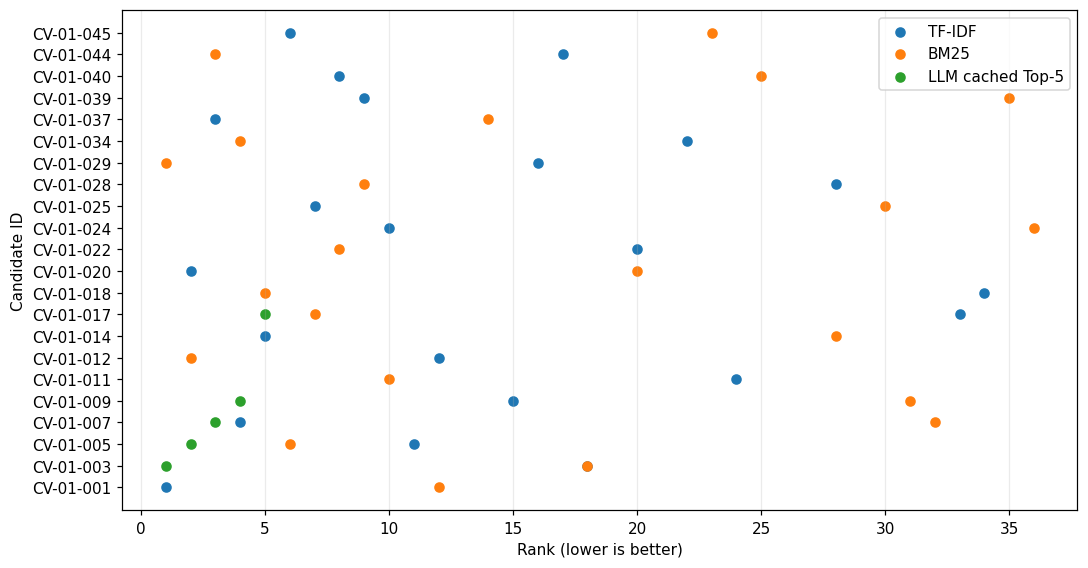

In [2]:
# The settings are intentionally explicit; change these after recording your prediction.
tfidf = match_tfidf(job_description, candidates, ngram_range=(1, 1),
                    max_features=None, min_df=1, max_df=1.0)
bm25 = match_bm25(job_description, candidates, k1=1.5, b=0.75)
llm = match_llm(JOB_ID, job_description, candidates, mode='cached')
rankings = {'TF-IDF': tfidf, 'BM25': bm25, 'LLM cached Top-5': llm}

top_five = pd.concat([
    frame.head(5)[['candidate_id', 'rank', 'score']].assign(algorithm=name)
    for name, frame in rankings.items()
], ignore_index=True)
display(top_five.pivot(index='rank', columns='algorithm', values='candidate_id'))
print('Pairwise shared candidates in Top 5:')
_, overlap = compare_rankings(rankings, k=5)
display(overlap)
fig, ax = plot_rankings(rankings, k=10)
plt.show()

### Observe Results

Mark the candidates that appear in more than one Top 5. Look at the rank plot: a candidate can be near the top for one method and far lower for another.

### Discussion

- Which candidates changed rank the most? Can you point to CV wording that may explain a lexical match?
- Did the LLM cite job-related evidence in its saved ranking report? A high score alone is not a reason.
- What independent relevance judgments would you need to call any ranking better?

**Key Takeaway:** A matching score measures a method's response to its inputs and settings; it is not a common quality scale or proof of candidate suitability.


### Problem 2 — How do parameters influence recommendations?

**Problem.** Reviewers say a strong candidate is missing from the first shortlist. Before changing the process, isolate which settings change the ranking.

### PAUSE & PREDICT — 2 minutes

Choose one setting you expect to have the greatest effect: adding bigrams, capping vocabulary, increasing `k1`, changing `b`, changing K, or editing an LLM requirement weight. Predict which candidate moves and why.

### Hands-on Exercise

Change one parameter at a time. Keep the JD and 50-CV pool fixed. For TF-IDF try unigram+bigrams and a `max_features` cap. For BM25 vary `k1` and `b`. Change K for the lexical methods. In live mode, a pair may edit `LLM_RUBRIC`, `SCORING_PROMPT`, or `LLM_MODEL`; the saved LLM cache is not recomputed when settings change. Temperature is supported by the workshop wrapper's custom-prompt path; leave it `None` if the model rejects it.


In [3]:
tfidf_changed = match_tfidf(job_description, candidates, ngram_range=(1, 2),
                              max_features=4000, min_df=1, max_df=1.0)
bm25_changed = match_bm25(job_description, candidates, k1=0.8, b=0.25)
changed = {'TF-IDF default': tfidf, 'TF-IDF (1,2)': tfidf_changed,
           'BM25 default': bm25, 'BM25 (k1=.8,b=.25)': bm25_changed}
rank_changes = pd.concat([
    frame.head(10)[['candidate_id', 'rank']].assign(configuration=name)
    for name, frame in changed.items()
], ignore_index=True)
display(rank_changes.pivot(index='candidate_id', columns='configuration', values='rank')
        .sort_values('TF-IDF default').head(15))
for k in [3, 5, 10]:
    print(f"\nTop-{k} overlap: TF-IDF default vs changed; BM25 default vs changed")
    _, table = compare_rankings(
        {'TF-IDF default': tfidf, 'TF-IDF changed': tfidf_changed,
         'BM25 default': bm25, 'BM25 changed': bm25_changed}, k=k)
    display(table)


Top-3 overlap: TF-IDF default vs changed; BM25 default vs changed

Top-5 overlap: TF-IDF default vs changed; BM25 default vs changed

Top-10 overlap: TF-IDF default vs changed; BM25 default vs changed


configuration,"BM25 (k1=.8,b=.25)",BM25 default,"TF-IDF (1,2)",TF-IDF default
candidate_id,,,,
CV-01-001,NaN,NaN,4.0,1.0
CV-01-020,NaN,NaN,3.0,2.0
CV-01-037,NaN,NaN,2.0,3.0
CV-01-007,NaN,NaN,1.0,4.0
CV-01-014,NaN,NaN,5.0,5.0
CV-01-045,NaN,NaN,6.0,6.0
CV-01-025,NaN,NaN,10.0,7.0
CV-01-040,NaN,NaN,9.0,8.0
CV-01-039,NaN,NaN,NaN,9.0


,left,right,shared_top_k,k
0,TF-IDF default,TF-IDF changed,2,3
1,TF-IDF default,BM25 default,0,3
2,TF-IDF default,BM25 changed,0,3
3,TF-IDF changed,BM25 default,0,3
4,TF-IDF changed,BM25 changed,0,3
5,BM25 default,BM25 changed,3,3


,left,right,shared_top_k,k
0,TF-IDF default,TF-IDF changed,5,5
1,TF-IDF default,BM25 default,0,5
2,TF-IDF default,BM25 changed,0,5
3,TF-IDF changed,BM25 default,0,5
4,TF-IDF changed,BM25 changed,0,5
5,BM25 default,BM25 changed,4,5


,left,right,shared_top_k,k
0,TF-IDF default,TF-IDF changed,8,10
1,TF-IDF default,BM25 default,0,10
2,TF-IDF default,BM25 changed,0,10
3,TF-IDF changed,BM25 default,0,10
4,TF-IDF changed,BM25 changed,0,10
5,BM25 default,BM25 changed,10,10


In [4]:
# Optional live LLM experiment. Cached mode above makes the notebook run without a key.
# Use only the fictional CVs supplied with this workshop. Live mode sends CV text to OpenRouter.
RUN_LIVE_LLM = False
LLM_MODEL = 'meta-llama/llama-3.3-70b-instruct'
SCORING_PROMPT = 'Assess only evidence of job-related skills, qualifications, and experience.'
LLM_RUBRIC = [
    {'text': 'Evidence of the technical skills specified in the job description', 'weight': 2},
    {'text': 'Evidence of relevant professional experience and responsibilities', 'weight': 2},
    {'text': 'Evidence of the required education or professional qualification', 'weight': 1},
]
LLM_TEMPERATURE = None  # Existing project scorer omits this; wrapper supports it on custom requests.
if RUN_LIVE_LLM:
    llm_live = match_llm(
        JOB_ID, job_description, candidates, mode='live', model=LLM_MODEL,
        rubric=LLM_RUBRIC, scoring_prompt=SCORING_PROMPT,
        temperature=LLM_TEMPERATURE,
    )
    display(llm_live.head(10)[['candidate_id', 'rank', 'score']])
else:
    print('Offline mode: displaying cached prior-project Top-5 output; no inference was run.')

Offline mode: displaying cached prior-project Top-5 output; no inference was run.


### Observe Results

Compare the rank tables and Top-K overlap after changing one setting. If top candidates move, identify whether the cause was a phrase match, repeated term, or document length. The cached LLM list is fixed at Top 5; live output requires the shared workshop key.

### Discussion

- Which single setting moved the most candidates? Was the movement relevant to the JD?
- Could a parameter change shift access for a group? What group evidence would you need?
- What independent and job-related relevance labels would justify retaining a setting?

**Key Takeaway:** Algorithm choice and configuration change who is recommended before historical decisions enter the picture.


### Problem 3 — Can historical hiring decisions introduce bias?

**Problem.** The team proposes learning from previous shortlists. Only now do we open the synthetic history. Historical decisions may reflect who was given opportunity, not only who was qualified.

### PAUSE & PREDICT — 3 minutes

If a candidate was not shortlisted, does that mean they were unqualified? If two candidates have similar qualifications, should sex or location affect who advances? What can we learn from outcomes recorded only after hiring?

### Hands-on Exercise

Load the history and inspect selection rates within this job. Compare groups overall and within synthetic qualification-score bands. Then separate shortlisted, hired, and performance-observed counts. Do not fill missing outcomes with zero.


In [5]:
history = load_history()
job_history = history.loc[history.job_id == JOB_ID].copy()
print(f"Synthetic history loaded for {JOB_ID}: {len(job_history)} applications")
for attribute in ['sex', 'geographic_location']:
    summary = job_history.groupby(attribute, observed=True).agg(
        applicants=('candidate_id', 'size'),
        mean_qualification=('simulated_qualification_score', 'mean'),
        shortlisted=('historical_shortlisted', 'sum'),
    )
    summary['shortlist_rate'] = summary.shortlisted / summary.applicants
    print(f"\nHistorical shortlist by {attribute}:")
    display(summary.round(3))

job_history['qualification_band'] = pd.qcut(
    job_history.simulated_qualification_score, q=3, duplicates='drop'
)
conditional = job_history.groupby(['qualification_band', 'sex'], observed=True).agg(
    applicants=('candidate_id', 'size'), shortlist_rate=('historical_shortlisted', 'mean')
).reset_index()
display(conditional.round(3))

Synthetic history loaded for JD-01: 50 applications

Historical shortlist by sex:

Historical shortlist by geographic_location:


,applicants,mean_qualification,shortlisted,shortlist_rate
sex,,,,
Man,19,64.847,7,0.368
Woman,31,62.784,3,0.097


,applicants,mean_qualification,shortlisted,shortlist_rate
geographic_location,,,,
Addis Ababa,28,63.496,7,0.250
Outside Addis Ababa,22,63.659,3,0.136


,qualification_band,sex,applicants,shortlist_rate
0,"(52.199000000000005, 61.233]",Man,5,0.000
1,"(52.199000000000005, 61.233]",Woman,12,0.000
2,"(61.233, 65.733]",Man,6,0.333
3,"(61.233, 65.733]",Woman,10,0.000
4,"(65.733, 74.3]",Man,8,0.625
5,"(65.733, 74.3]",Woman,9,0.333


In [6]:
job_history['shortlist_status'] = job_history.historical_shortlisted.map(
    {0: 'Not shortlisted', 1: 'Shortlisted'}
)
job_history['hire_status'] = job_history.historical_hired.map(
    {0.0: 'Shortlisted, not hired', 1.0: 'Hired'}
).fillna('No hiring decision: not shortlisted')
coverage = job_history.groupby('hire_status', observed=True).agg(
    applications=('candidate_id', 'size'),
    performance_observed=('performance_observed', 'sum'),
    mean_performance_when_observed=('post_hire_performance', 'mean'),
)
display(coverage)
print('Blank historical_hired values:', int(job_history.historical_hired.isna().sum()))
print('Blank post_hire_performance values:', int(job_history.post_hire_performance.isna().sum()))

Blank historical_hired values: 40
Blank post_hire_performance values: 45


,applications,performance_observed,mean_performance_when_observed
hire_status,,,
Hired,5,5,3.54
No hiring decision: not shortlisted,40,0,NaN
"Shortlisted, not hired",5,0,NaN


### Observe Results

Look for a shortlist-rate difference between groups. Compare it within qualification bands, not only across the full pool. Then trace the missingness: `historical_hired` is unknown for people never shortlisted; performance is observed only for people who were hired.

### Discussion

- Are the group differences visible within qualification bands? What else could explain them?
- Can we know how rejected or non-hired candidates would have performed? What additional evidence would help?
- What bias could result from training only on observed decisions or outcomes?

**Key Takeaway:** Historical decisions are not neutral ground truth, and selectively observed outcomes cannot tell us what would have happened to excluded candidates.


### Problem 4 — Are the matching algorithms fair?

**Problem.** The team wants to compare who reaches review under each algorithm. Fairlearn can measure group differences in decisions. It cannot decide whether a difference is justified or prove discrimination.

Selection rate and demographic parity difference/ratio require group labels and decisions. Group performance metrics and equalized odds also require reference labels. Here, the available hire label is selectively observed and the historical shortlist label is potentially biased. We will report selection metrics and show historical agreement only as agreement, not correctness. We will not calculate equalized odds from these labels. A helper is included for performance metrics when independent, complete labels exist; it requires an explicit validity flag.

### PAUSE & PREDICT — 3 minutes

If one group's selection rate is lower, is that automatically evidence of discrimination? Which algorithm might have the smallest gap? What happens when K changes?

### Hands-on Exercise

Use K=5 for a like-for-like comparison across TF-IDF, BM25, and the cached LLM list. Calculate Fairlearn selection rates separately by sex and geography, with group sample counts. Then vary K for TF-IDF and BM25. Do not pool unrelated jobs into one denominator.


TF-IDF {'demographic_parity_difference': 0.008488964346349742, 'demographic_parity_ratio': 0.9193548387096775}
BM25 {'demographic_parity_difference': 0.09337860780984719, 'demographic_parity_ratio': 0.40860215053763443}
LLM cached Top-5 {'demographic_parity_difference': 0.008488964346349742, 'demographic_parity_ratio': 0.9193548387096775}


,algorithm,sex,selection_rate,n
0,TF-IDF,Man,0.105263,19
1,TF-IDF,Woman,0.096774,31
2,BM25,Man,0.157895,19
3,BM25,Woman,0.064516,31
4,LLM cached Top-5,Man,0.105263,19
5,LLM cached Top-5,Woman,0.096774,31


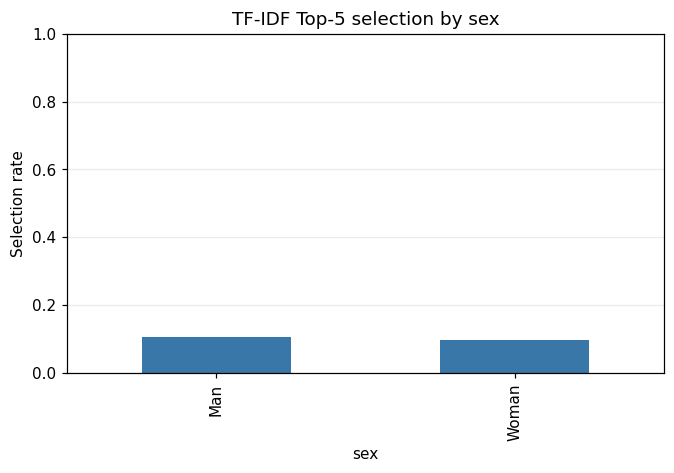

In [7]:
selection_by_method = {}
fairness_rows = []
for name, ranking in rankings.items():
    selection = prepare_group_selection_data(
        ranking, history, job_id=JOB_ID, k=5, group='sex'
    )
    selection_by_method[name] = selection
    group_rates, disparity = fairness_metrics(selection, 'sex')
    group_rates.insert(0, 'algorithm', name)
    fairness_rows.append(group_rates)
    print(name, disparity)
sex_results = pd.concat(fairness_rows, ignore_index=True)
display(sex_results)
fig, ax = plot_group_rates(sex_results.loc[sex_results.algorithm == 'TF-IDF'],
                           group='sex', title='TF-IDF Top-5 selection by sex')
plt.show()

In [8]:
# Geography audit and reference agreement are separate questions.
geo_results = []
agreement_results = []
for name, ranking in rankings.items():
    selection = prepare_group_selection_data(
        ranking, history, job_id=JOB_ID, k=5, group='geographic_location'
    )
    rates, disparity = fairness_metrics(selection, 'geographic_location')
    rates.insert(0, 'algorithm', name)
    rates['demographic_parity_difference'] = disparity['demographic_parity_difference']
    rates['demographic_parity_ratio'] = disparity['demographic_parity_ratio']
    geo_results.append(rates)
    agreement_results.append(
        group_agreement_metrics(selection_by_method[name], 'sex')
        .assign(algorithm=name)
    )
display(pd.concat(geo_results, ignore_index=True))
print('Agreement with the historical shortlist (not correctness):')
display(pd.concat(agreement_results, ignore_index=True))

Agreement with the historical shortlist (not correctness):


,algorithm,geographic_location,selection_rate,n,demographic_parity_difference,demographic_parity_ratio
0,TF-IDF,Addis Ababa,0.071429,28,0.064935,0.523810
1,TF-IDF,Outside Addis Ababa,0.136364,22,0.064935,0.523810
2,BM25,Addis Ababa,0.071429,28,0.064935,0.523810
3,BM25,Outside Addis Ababa,0.136364,22,0.064935,0.523810
4,LLM cached Top-5,Addis Ababa,0.142857,28,0.097403,0.318182
5,LLM cached Top-5,Outside Addis Ababa,0.045455,22,0.097403,0.318182


,sex,agreement_rate,algorithm
0,Man,0.526316,TF-IDF
1,Woman,0.806452,TF-IDF
2,Man,0.578947,BM25
3,Woman,0.903226,BM25
4,Man,0.736842,LLM cached Top-5
5,Woman,0.806452,LLM cached Top-5


In [9]:
# The available hire outcome is selective and is not a complete performance label.
try:
    fairness_metrics_with_reference_labels(
        selection_by_method['TF-IDF'], 'sex', job_history.historical_hired,
        labels_are_independent_and_complete=False,
    )
except ValueError as exc:
    print('Performance/equalized-odds metrics skipped:', exc)
print('Historical shortlist agreement is not correctness; post-hire performance is observed only for hires.')

Performance/equalized-odds metrics skipped: Independent complete reference labels are required
Historical shortlist agreement is not correctness; post-hire performance is observed only for hires.


In [10]:
# K sensitivity: offline cached LLM results contain Top-5 only, so vary K for lexical methods.
k_sensitivity = []
for method, ranking in [('TF-IDF', tfidf), ('BM25', bm25)]:
    for k in [1, 3, 5, 10]:
        selected = prepare_group_selection_data(ranking, history, job_id=JOB_ID, k=k, group='sex')
        rates, disparity = fairness_metrics(selected, 'sex')
        k_sensitivity.append({'algorithm': method, 'k': k, **disparity})
display(pd.DataFrame(k_sensitivity))

,algorithm,k,demographic_parity_difference,demographic_parity_ratio
0,TF-IDF,1,0.052632,0.000000
1,TF-IDF,3,0.073005,0.306452
2,TF-IDF,5,0.008489,0.919355
3,TF-IDF,10,0.016978,0.919355
4,BM25,1,0.052632,0.000000
5,BM25,3,0.073005,0.306452
6,BM25,5,0.093379,0.408602
7,BM25,10,0.101868,0.612903


### Observe Results

Read each group count beside its rate. Compare demographic parity difference and ratio; they summarize selection decisions, not qualification or performance. Compare historical agreement separately. Small applicant pools make rates sensitive to a few people.

### Discussion

- Which method's selection rates differ most? Does a smaller difference imply better matching?
- How does K change group access? Do rates move smoothly?
- What does agreement with the old shortlist say—and not say?
- Why is equalized odds unsupported here? What validated outcome evidence would be needed?

**Key Takeaway:** Fairlearn quantifies group differences in the decisions and labels we provide; it cannot repair missing labels or certify fairness.


### Problem 5 — Which approach should the team advance?

**Problem.** The team must recommend a next step without pretending this small synthetic exercise establishes a winner.

### PAUSE & PREDICT — 2 minutes

Would you advance the highest-scoring method, the method with the smallest selection gap, a human-reviewed combination, or none yet? Write down the evidence threshold behind your choice.

### Hands-on Group Exercise

Complete the decision table from your observed rank overlap, parameter stability, group rates, and label coverage. Use the LLM cached result only as a saved prior top-five list. Name at least one new source of evidence needed before real use.


In [11]:
decision_evidence = pd.DataFrame([
    {'method': name,
     'Top-5 IDs': ', '.join(select_top_k(ranking, 5).candidate_id.tolist()),
     'Top-5 overlap with TF-IDF': (
         len(set(select_top_k(ranking, 5).candidate_id) & set(select_top_k(tfidf, 5).candidate_id))
         if name != 'TF-IDF' else 5
     ),
     'K coverage': 'complete ranking' if name != 'LLM cached Top-5' else 'cached Top-5 only',
    }
    for name, ranking in rankings.items()
])
display(decision_evidence)
print('Evidence boundary: selection is observable for the full pool; post-hire performance is observed only for hired candidates.')

Evidence boundary: selection is observable for the full pool; post-hire performance is observed only for hired candidates.


,method,Top-5 IDs,Top-5 overlap with TF-IDF,K coverage
0,TF-IDF,"CV-01-001, CV-01-020, CV-01-037, CV-01-007, CV-01-014",5,complete ranking
1,BM25,"CV-01-029, CV-01-012, CV-01-044, CV-01-034, CV-01-018",0,complete ranking
2,LLM cached Top-5,"CV-01-003, CV-01-005, CV-01-007, CV-01-009, CV-01-017",1,cached Top-5 only


### Observe Results

Review the comparison table alongside the earlier fairness and coverage outputs. Identify which statements are directly supported by the run and which would require new evidence.

### Discussion

As a group, recommend **advance**, **revise and re-evaluate**, or **do not advance**. State:

1. What evidence supports the recommendation?
2. What is unknown because of missing performance outcomes or cached LLM scope?
3. Which human review, independent labels, or prospective evidence would change your mind?
4. Who should be responsible for collecting that evidence and reviewing the result?

### Final Reflection

Say one thing you can conclude from this exercise and one thing you cannot conclude. The intended answer is not a universal fairest algorithm; it is a defensible account of the evidence and its limits.

**Key Takeaway:** The right decision depends on job-related evidence, valid outcome labels, group context, and accountable human review—not on one score or parity statistic.
